EXAMPLE CODE FOR CONTROLLING THORLABS CAMERA, FILTER WHEEL AND LASER

In [1]:
%load_ext autoreload
%autoreload 2

#__________________________________________________G1 SCAN 18/06/2025 : Optimisation loop integrated________________________________________________________

import numpy as np
import Components as comp
import time
import socket
import sys
import os
import matplotlib.pyplot as plt

if socket.gethostname() == "ph-photonbec5":
    sys.path.append("D:/Control/PythonPackages/")
from pbec_analysis import make_timestamp,ExperimentalDataSet, CameraData

components = dict()
filter_wheel = comp.FilterWheel(allowed_filter_positions=[0, 1, 2, 3, 4, 5])
laser = comp.Toptica_Laser()

def save_image(image,stage_position,exposure_time,pwr):
    timestamp = make_timestamp(precision=0)
    dataset = ExperimentalDataSet(timestamp)
    camera_data = CameraData(timestamp,extension='_' + str(round(stage_position,1)) + '_' + str(pwr) + '_' + str(int(exposure_time)) + '_' + str(np.amax(image)) + '_single' + '.png')
    camera_data.data = image
    dataset.dataset["CavityCamera" + str(stage_position) + str(pwr) + str(exposure_time) + str(np.amax(image))+ 'single'] = camera_data
    dataset.saveAllData()
    time.sleep(0.2)

def verify_samples(n,lower,upper):
    maxs = []
    for k in range(n):
        img = camera.get_image()
        max_pixel = np.amax(img)
        maxs.append(max_pixel)

    for i in range(len(maxs)):
        count_sat = sum(1 for x in maxs if x == 255)
        count_usat = sum(1 for x in maxs if x < lower)
        count_good = sum(1 for x in maxs if lower <= x <= upper)
    result =[count_sat,count_usat,count_good]

    if count_sat == max(result):
        return 'sat'
    if count_usat == max(result):
        return 'usat'
    if count_good == max(result):
        return 'good'
    else:
        return 'retry'

def find_optimal_exposure_and_filter(camera, filter_wheel, n, min_exp, max_exp, lower, upper):
    """
    Optimize camera exposure and filter wheel position based on pixel intensity sampling.
    Returns optimal exposure and filter position.
    """
    filter_position = 0

    try:
        flag = verify_samples(n, lower, upper)
    except Exception as e:
        print("Error verifying samples:", e)
        return None, None

    iteration = 0

    while flag != 'good':
        iteration += 1
        exposure = camera.get_exposure()

        if flag == 'sat':
            if exposure > min_exp:
                camera.change_exposure(exposure - 1000)
                print('Decreased exposure to:', camera.get_exposure())
            elif exposure <= min_exp:
                camera.change_exposure(min_exp)
                if filter_position + 1 > 5:
                    print("Reached max filter position. Stopping.")
                    break
                filter_position += 1
                filter_wheel.set(filter_position)
                print("Increased filter position to:", filter_position)

        elif flag == 'usat':
            if exposure >= max_exp:
                print("Max exposure exceeded.")
                if filter_position - 1 < 0:
                    print("Reached min filter position. Stopping.")
                    break
                filter_position -= 1
                filter_wheel.set(filter_position)
                print("Decreased filter position to:", filter_position)
            else:
                camera.change_exposure(exposure + 1000)
                print("Increased exposure to:", camera.get_exposure())

        try:
            flag = verify_samples(n, lower, upper)
        except Exception as e:
            print("Camera error during verification:", e)
            print("Setting lastly tested parameters")
            return camera.get_exposure(), filter_position
        print("Flag after iteration", iteration, ":", flag)
        time.sleep(0.1)

    print("Optimal parameters found in", iteration, "iterations.")
    return camera.get_exposure(), filter_position


position_list = np.append(np.arange(0, 50, 5), np.arange(50, 650, 50))
power_list = np.append(np.append(np.arange(28.3,28.8,0.05)/1000,np.arange(28.8,29.8,0.1)/1000),np.arange(29.8,31.8,0.2)/1000) #CHANGE HERE


min_exp = 100 #Minimum exposure time for the camera
max_exp = 31100 #Maximum exposure time for camera, !!! Might crash before reaching 41100

n = 15 #number of pictures for the optimisation loop
n_sample = 3 #number of pictures taken at each stage position
lower = 150 #lowest pixel value limit for optimal picture
upper = 254 #highest pixel value limit for optimal picture



with comp.Thor_Camera(min_exp, max_exp, measure=True, max_frames=1) as camera:
    with comp.Translation_Stage() as stage:

        for power in power_list:

            laser.set(power)
            print('Starting scan for power: ', power*1000, ' mW')

            #Setting up initial parameters
            stage.set(position_list[0])
            filter_position = 0
            filter_wheel.set(filter_position)
            camera.change_exposure(1100)

            #Optimisation loop
            print('Starting optimisation loop')
            optimal_exp, optimal_filter = find_optimal_exposure_and_filter(
                camera, filter_wheel, n, min_exp, max_exp, lower, upper)

            print("Optimal Exposure:", optimal_exp)
            print("Optimal Filter Position:", optimal_filter)
            camera.change_exposure(optimal_exp)
            filter_wheel.set(optimal_filter)

            #Measurement starting
            for k in range(len(position_list)):
                stage.set(position_list[k])
                pos = stage.get_position()
                print('Now at position : ', pos)
                for n in range(n_sample):
                    img = camera.get_image()
                    save_image(img,pos, optimal_exp,power*1000)

                #Midway optimisation loop
                if k == len(position_list)//2 :
                    print('Starting midway optimisation loop')
                    optimal_exp, optimal_filter = find_optimal_exposure_and_filter(
                        camera, filter_wheel, n, min_exp, max_exp, lower, upper)

                    print("Optimal Exposure:", optimal_exp)
                    print("Optimal Filter Position:", optimal_filter)
                    camera.change_exposure(optimal_exp)
                    filter_wheel.set(optimal_filter)
        laser.set(0)

C:\Users\photonbec\AppData\Local\Programs\Python\Python38-32\lib\site-packages\pylablib\devices\Thorlabs\kinesis.py:230: UserWarning: model number BBD201 doesn't match the device ID prefix 73(BBD103)
  warnings.warn("model number {} doesn't match the device ID prefix {}({})".format(model_no,port,port_model_no))


Starting scan for power:  28.3  mW
Starting optimisation loop
Increased exposure to: 2100
Flag after iteration 1 : usat
Increased exposure to: 3100
Flag after iteration 2 : usat
Increased exposure to: 4100
Flag after iteration 3 : good
Optimal parameters found in 3 iterations.
Optimal Exposure: 4100
Optimal Filter Position: 0
Now at position :  0.0
Now at position :  5.0
Now at position :  10.0
Now at position :  15.0
Now at position :  20.0
Now at position :  25.0
Now at position :  30.0
Now at position :  35.0
Now at position :  40.0
Now at position :  45.0
Now at position :  50.0
Now at position :  100.0
Starting midway optimisation loop
Optimal parameters found in 0 iterations.
Optimal Exposure: 4100
Optimal Filter Position: 0
Now at position :  150.0
Now at position :  200.00005
Now at position :  250.0
Now at position :  300.00005
Now at position :  350.0
Now at position :  400.0
Now at position :  450.0
Now at position :  500.0
Now at position :  550.00005
Now at position :  600

In [1]:
exposure_list = np.arange(100,41100,1000)
print(exposure_list)

NameError: name 'np' is not defined

usat
New exposure is : 2100
usat
New exposure is : 3100
usat
New exposure is : 4100
usat
New exposure is : 5100
good
4 5100 159.28152492668622


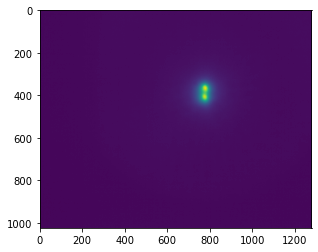

In [1]:
%load_ext autoreload
%autoreload 2

#__________________________________________________BETA VERSION OF OPTIMISATION LOOOP________________________________________________________(We need lower exposure time)

import numpy as np
import Components as comp
import time
import socket
import sys
import os
import matplotlib.pyplot as plt

if socket.gethostname() == "ph-photonbec5":
    sys.path.append("D:/Control/PythonPackages/")
from pbec_analysis import make_timestamp,ExperimentalDataSet, CameraData
components = dict()
filter_wheel = comp.FilterWheel(allowed_filter_positions=[0, 1, 2, 3, 4, 5])

def save_image(image,stage_position,exposure_time,pwr):
    timestamp = make_timestamp(precision=0)
    dataset = ExperimentalDataSet(timestamp)
    camera_data = CameraData(timestamp,extension='_' + str(round(stage_position,1)) + '_' + str(pwr) + '_' + str(int(exposure_time)) + '_' + str(np.amax(image)) + '_single' + '.png')
    camera_data.data = image
    dataset.dataset["CavityCamera" + str(stage_position) + str(pwr) + str(exposure_time) + str(np.amax(image))+ 'single'] = camera_data
    dataset.saveAllData()
    time.sleep(0.2)


def verify_samples(n,lower,upper):
    maxs = []
    for k in range(n):
        img = camera.get_image()
        max_pixel = np.amax(img)
        maxs.append(max_pixel)

    for i in range(len(maxs)):
        count_sat = sum(1 for x in maxs if x == 255)
        count_usat = sum(1 for x in maxs if x < lower)
        count_good = sum(1 for x in maxs if lower <= x <= upper)
    result =[count_sat,count_usat,count_good]

    if count_sat == max(result):
        return 'sat'
    if count_usat == max(result):
        return 'usat'
    if count_good == max(result):
        return 'good'
    else:
        return 'retry'



def find_optimal_exposure_and_filter(camera, filter_wheel, n, min_exp, max_exp, lower, upper):
    """
    Optimize camera exposure and filter wheel position based on pixel intensity sampling.
    Returns optimal exposure and filter position.
    """
    filter_position = 0
    camera.change_exposure(1100)

    try:
        flag = verify_samples(n, lower, upper)
    except Exception as e:
        print("Error verifying samples:", e)
        return None, None

    iteration = 0

    while flag != 'good':
        iteration += 1
        exposure = camera.get_exposure()

        if flag == 'sat':
            if exposure > min_exp:
                camera.change_exposure(exposure - 1000)
                print('Decreased exposure to:', camera.get_exposure())
            elif exposure <= min_exp:
                camera.change_exposure(min_exp)
                if filter_position + 1 > 5:
                    print("Reached max filter position. Stopping.")
                    break
                filter_position += 1
                filter_wheel.set(filter_position)
                print("Increased filter position to:", filter_position)

        elif flag == 'usat':
            if exposure >= max_exp:
                print("Max exposure exceeded.")
                if filter_position - 1 < 0:
                    print("Reached min filter position. Stopping.")
                    break
                filter_position -= 1
                filter_wheel.set(filter_position)
                print("Decreased filter position to:", filter_position)
            else:
                camera.change_exposure(exposure + 1000)
                print("Increased exposure to:", camera.get_exposure())

        try:
            flag = verify_samples(n, lower, upper)
        except Exception as e:
            print("Camera error during verification:", e)
            return None, None
        print("Flag after iteration", iteration, ":", flag)

    print("Optimal parameters found in", iteration, "iterations.")
    return camera.get_exposure(), filter_position


position_list = np.append(np.append(np.arange(0,90,5),np.arange(90,300,10)),np.arange(300,630,30))
power_list = np.append(np.append(np.arange(35,70,1)/1000,np.arange(70,100,5)/1000),np.arange(100,150,10)/1000) #CHANGE HERE
min_exp = 100
max_exp = 61100
pixel_selection_range = [190,255]
n = 10
lower = 150
upper = 254

with comp.Thor_Camera(min_exp, max_exp, measure=True, max_frames=1) as camera:

    #First settings :
    filter_position = 0

    camera.change_exposure(1100)
    #Optimal parameters search loop :
    print(verify_samples(n,lower,upper))
    flag = verify_samples(n,lower,upper)
    iteration = 0
    while flag != 'good':
        iteration += 1

        if flag == 'sat':
            exposure = camera.get_exposure()
            if exposure > min_exp:
                camera.change_exposure(exposure-1000)
                print('New exposure is :', camera.get_exposure())

            if exposure <= min_exp:
                camera.change_exposure(min_exp)
                if filter_position+1 > 5:
                    break
                else:
                    filter_position += 1
                    filter_wheel.set(filter_position)
                    print('New filter position is :', filter_position)

                print('New exposure is :', camera.get_exposure())
            try:
                flag = verify_samples(n,lower,upper)
            except:
                print('Camera has crashed')
                break
            print(flag)
        if flag == 'usat':
            exposure = camera.get_exposure()
            if exposure >= max_exp:
                print('Max exposure exceeded, quitting optmisation loop')
                if filter_position-1 < 0:
                    break
                else:
                    filter_position -= 1
                    filter_wheel.set(filter_position)
                    print('New filter position is :', filter_position)

            if exposure < max_exp:
                camera.change_exposure(exposure+1000)
                print('New exposure is :', camera.get_exposure())
            try:
                flag = verify_samples(n,lower,upper)
            except:
                print('Camera has crashed')
                break
            print(flag)

        else :
            flag = verify_samples(n,lower,upper)
            print(flag)
    img = camera.get_image()
    plt.imshow(img)
    print(iteration,camera.get_exposure(),np.amax(img))

In [1]:
%load_ext autoreload
%autoreload 2

#__________________________________________________LAST VERSION OF OPTIMISATION LOOOP________________________________________________________

import numpy as np
import Components as comp
import time
import socket
import sys
import os
import matplotlib.pyplot as plt

if socket.gethostname() == "ph-photonbec5":
    sys.path.append("D:/Control/PythonPackages/")
from pbec_analysis import make_timestamp,ExperimentalDataSet, CameraData

components = dict()
filter_wheel = comp.FilterWheel(allowed_filter_positions=[0, 1, 2, 3, 4, 5])
laser = comp.Toptica_Laser()

def save_image(image,stage_position,exposure_time,pwr):
    timestamp = make_timestamp(precision=0)
    dataset = ExperimentalDataSet(timestamp)
    camera_data = CameraData(timestamp,extension='_' + str(round(stage_position,1)) + '_' + str(pwr) + '_' + str(int(exposure_time)) + '_' + str(np.amax(image)) + '_single' + '.png')
    camera_data.data = image
    dataset.dataset["CavityCamera" + str(stage_position) + str(pwr) + str(exposure_time) + str(np.amax(image))+ 'single'] = camera_data
    dataset.saveAllData()
    time.sleep(0.2)

def verify_samples(n,lower,upper):
    maxs = []
    for k in range(n):
        img = camera.get_image()
        max_pixel = np.amax(img)
        maxs.append(max_pixel)

    for i in range(len(maxs)):
        count_sat = sum(1 for x in maxs if x == 255)
        count_usat = sum(1 for x in maxs if x < lower)
        count_good = sum(1 for x in maxs if lower <= x <= upper)
    result =[count_sat,count_usat,count_good]

    if count_sat == max(result):
        return 'sat'
    if count_usat == max(result):
        return 'usat'
    if count_good == max(result):
        return 'good'
    else:
        return 'retry'

def find_optimal_exposure_and_filter(camera, filter_wheel, n, min_exp, max_exp, lower, upper):
    """
    Optimize camera exposure and filter wheel position based on pixel intensity sampling.
    Returns optimal exposure and filter position.
    """
    filter_position = 0

    try:
        flag = verify_samples(n, lower, upper)
    except Exception as e:
        print("Error verifying samples:", e)
        return None, None

    iteration = 0

    while flag != 'good':
        iteration += 1
        exposure = camera.get_exposure()

        if flag == 'sat':
            if exposure > min_exp:
                camera.change_exposure(exposure - 1000)
                print('Decreased exposure to:', camera.get_exposure())
            elif exposure <= min_exp:
                camera.change_exposure(min_exp)
                if filter_position + 1 > 5:
                    print("Reached max filter position. Stopping.")
                    break
                filter_position += 1
                filter_wheel.set(filter_position)
                print("Increased filter position to:", filter_position)

        elif flag == 'usat':
            if exposure >= max_exp:
                print("Max exposure exceeded.")
                if filter_position - 1 < 0:
                    print("Reached min filter position. Stopping.")
                    break
                filter_position -= 1
                filter_wheel.set(filter_position)
                print("Decreased filter position to:", filter_position)
            else:
                camera.change_exposure(exposure + 1000)
                print("Increased exposure to:", camera.get_exposure())

        try:
            flag = verify_samples(n, lower, upper)
        except Exception as e:
            print("Camera error during verification:", e)
            print("Setting lastly tested parameters")
            return camera.get_exposure(), filter_position
        print("Flag after iteration", iteration, ":", flag)
        time.sleep(0.1)

    print("Optimal parameters found in", iteration, "iterations.")
    return camera.get_exposure(), filter_position


position_list = np.append(np.append(np.arange(0,100,20),np.arange(100,300,50)),np.arange(300,600,100))
power_list = np.append(np.append(np.arange(35,70,1)/1000,np.arange(70,100,5)/1000),np.arange(100,150,10)/1000) #CHANGE HERE
power_list = np.array([30,34])/1000

min_exp = 100 #Minimum exposure time for the camera
max_exp = 31100 #Maximum exposure time for camera, !!! Might crash before reaching 41100

n = 15 #number of pictures for the optimisation loop
n_sample = 3 #number of pictures taken at each stage position
lower = 150 #lowest pixel value limit for optimal picture
upper = 254 #highest pixel value limit for optimal picture



with comp.Thor_Camera(min_exp, max_exp, measure=True, max_frames=1) as camera:
    with comp.Translation_Stage() as stage:

        for power in power_list:

            laser.set(power)
            print('Starting scan for power: ', power*1000, ' mW')

            #Setting up initial parameters
            stage.set(position_list[0])
            filter_position = 0
            filter_wheel.set(filter_position)
            camera.change_exposure(1100)

            #Optimisation loop
            print('Starting optimisation loop')
            optimal_exp, optimal_filter = find_optimal_exposure_and_filter(
                camera, filter_wheel, n, min_exp, max_exp, lower, upper)

            print("Optimal Exposure:", optimal_exp)
            print("Optimal Filter Position:", optimal_filter)
            camera.change_exposure(optimal_exp)
            filter_wheel.set(optimal_filter)

            #Measurement starting
            for k in range(len(position_list)):
                stage.set(position_list[k])
                pos = stage.get_position()
                print('Now at position : ', pos)
                for n in range(n_sample):
                    img = camera.get_image()
                    save_image(img,pos, optimal_exp,power*1000)

                #Midway optimisation loop
                if k == len(position_list)//2 :
                    print('Starting midway optimisation loop')
                    optimal_exp, optimal_filter = find_optimal_exposure_and_filter(
                        camera, filter_wheel, n, min_exp, max_exp, lower, upper)

                    print("Optimal Exposure:", optimal_exp)
                    print("Optimal Filter Position:", optimal_filter)
                    camera.change_exposure(optimal_exp)
                    filter_wheel.set(optimal_filter)



C:\Users\photonbec\AppData\Local\Programs\Python\Python38-32\lib\site-packages\pylablib\devices\Thorlabs\kinesis.py:230: UserWarning: model number BBD201 doesn't match the device ID prefix 73(BBD103)
  warnings.warn("model number {} doesn't match the device ID prefix {}({})".format(model_no,port,port_model_no))


Starting scan for power:  30.0  mW
Starting optimisation loop
Decreased exposure to: 100
Flag after iteration 1 : sat
Increased filter position to: 1
Flag after iteration 2 : sat
Increased filter position to: 2
Flag after iteration 3 : sat
Increased filter position to: 3
Flag after iteration 4 : good
Optimal parameters found in 4 iterations.
Optimal Exposure: 100
Optimal Filter Position: 3
Now at position :  0.0
Now at position :  20.0
Now at position :  40.0
Now at position :  60.0
Now at position :  80.00005
Now at position :  100.0
Now at position :  150.0
Starting midway optimisation loop
Increased exposure to: 1100
Flag after iteration 1 : usat
Increased exposure to: 2100
Flag after iteration 2 : usat
Increased exposure to: 3100
Flag after iteration 3 : usat
Increased exposure to: 4100
Flag after iteration 4 : usat
Increased exposure to: 5100
Flag after iteration 5 : usat
Increased exposure to: 6100
Flag after iteration 6 : usat
Increased exposure to: 7100
Flag after iteration 7 :